# 03 - Módulo 2: Pronóstico de casos de dengue (RNN / LSTM)

**Proyecto 2: VectorIA** - Colegio Universitario de Cartago (CUC)

**Integrantes:** Mariana Méndez Pérez · Luis Diego Montero Vargas · Nadin Rojas López · Claret Rodríguez Jiménez

Objetivo: predecir los casos de dengue de las próximas 4 semanas usando las últimas 26 semanas de casos, clima (lluvia, temperatura y humedad) y fecha.

Seguimos los mismos pasos del ejercicio de clase RNN-Forecast, con los cambios que pide el proyecto:
- Varias variables de entrada en lugar de una.
- Se predicen 4 semanas a la vez (Dense de 4 neuronas).
- Se compara un modelo base SimpleRNN contra el LSTM, y los dos contra el baseline estacional (misma semana del año anterior).
- Al final se pronostican 2025 y 2026 repitiendo el pronóstico como en el forecast de clase: las primeras 4 semanas como pronóstico y el resto como escenarios, con el clima real de NASA POWER.

# 1.Importación librerías

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' # Oculta los mensajes internos de TensorFlow

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')

# 2.Importación fuente de datos

In [2]:
# Usamos los datos procesados en el EDA (01_EDA.ipynb), con la fecha como índice
df = pd.read_csv('../data/processed/dengue_nacional_procesado.csv', index_col='fecha_inicio_semana', parse_dates=True)

In [3]:
df.head()

,anio,semana_epi,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,mes,log_casos,log_lluvia,lluvia_4sem,baseline_estacional,temp_min_c_lag6,temp_min_c_lag8,log_lluvia_lag3,log_lluvia_lag4,humedad_rel_pct_lag1,humedad_rel_pct_lag2
fecha_inicio_semana,,,,,,,,,,,,,,,,,,,
2013-12-29,2014,1,239,4.62,11.0,27.2,19.9,84.9,12,5.476464,2.484907,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-01-05,2014,2,257,4.97,8.9,27.0,19.7,83.8,1,5.549076,2.292535,NaN,NaN,NaN,NaN,NaN,NaN,84.9,NaN
2014-01-12,2014,3,184,3.56,4.5,27.1,19.5,81.7,1,5.214936,1.704748,NaN,NaN,NaN,NaN,NaN,NaN,83.8,84.9
2014-01-19,2014,4,156,3.02,7.7,27.1,19.5,80.0,1,5.049856,2.163323,32.1,NaN,NaN,NaN,2.484907,NaN,81.7,83.8
2014-01-26,2014,5,189,3.66,4.7,27.2,18.7,78.0,1,5.241747,1.740466,25.8,NaN,NaN,NaN,2.292535,2.484907,80.0,81.7


Cada fila es una semana, desde el 29 de diciembre de 2013 hasta el 22 de diciembre de 2024. Además de los casos y el clima, el archivo ya trae las columnas que creamos en el EDA, como log_casos y log_lluvia.

In [4]:
len(df)

574

# 3.Preprocesado

## 3.1Visualización de la secuencia

<Axes: xlabel='fecha_inicio_semana'>

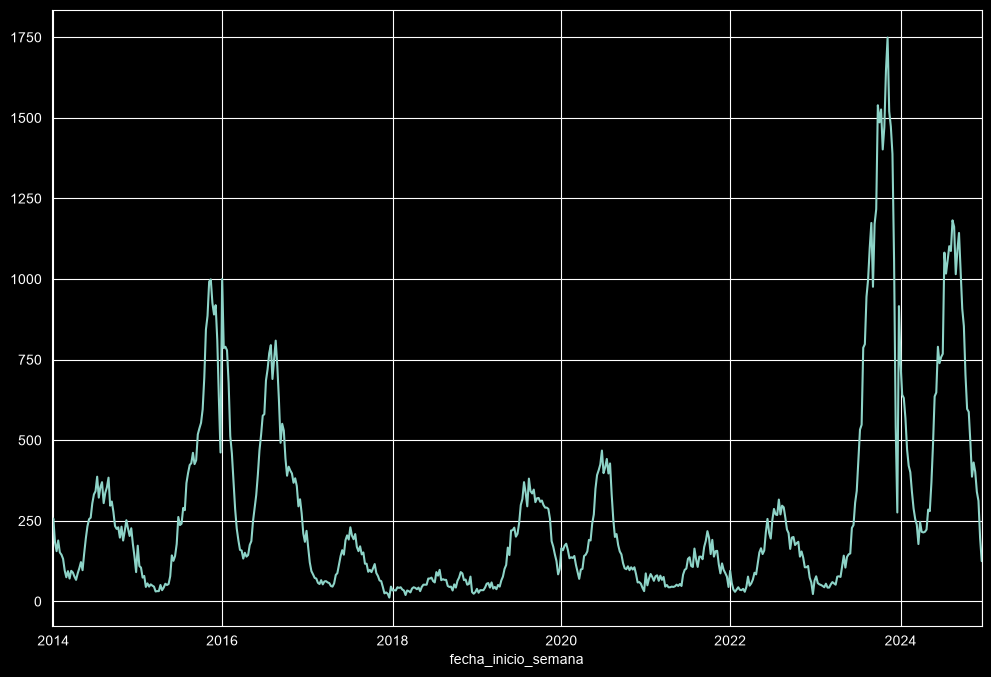

In [5]:
df['casos_dengue'].plot(figsize=(12,8))

<Axes: xlabel='fecha_inicio_semana'>

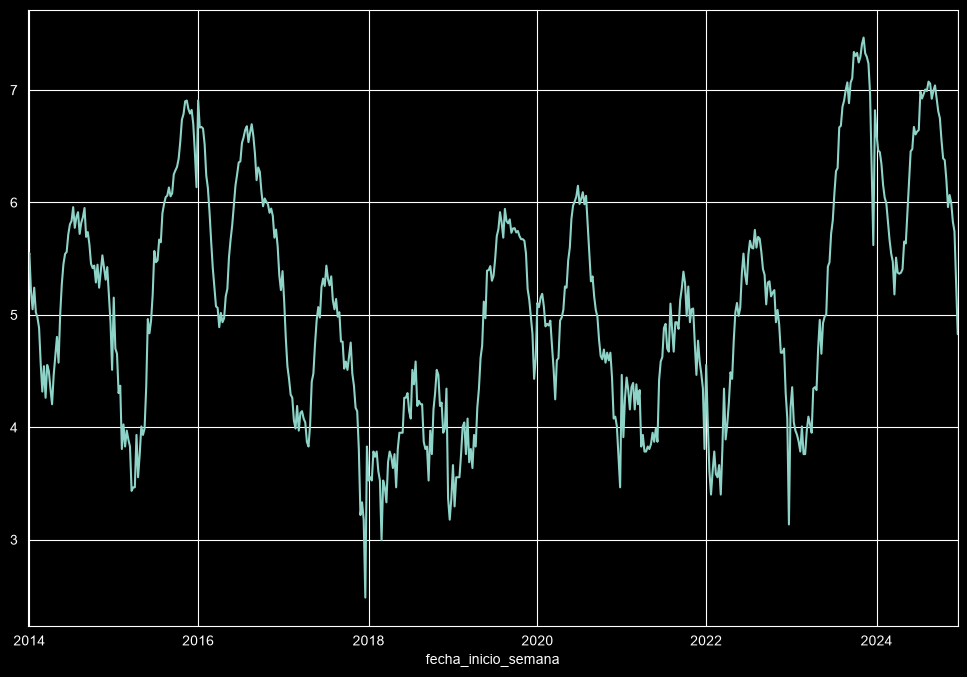

In [6]:
# En logaritmo los brotes ya no dominan la escala (decisión tomada en el EDA)
df['log_casos'].plot(figsize=(12,8))

### Interpretación
En el primer gráfico los brotes de 2023 y 2024 son tan altos que los años tranquilos casi no se ven. En logaritmo todos los años quedan en una escala parecida y se ve mejor el patrón que se repite cada año: los casos bajan a inicios de año y suben a mitad de año. Por eso el modelo trabaja con log_casos.

## 3.2 Variables de entrada
Usamos las variables que salieron mejor en el EDA: los casos pasados (log_casos), la temperatura mínima, la lluvia en logaritmo y la humedad. También la temperatura máxima, que la pide el proyecto.

La fecha la agregamos como seno y coseno de la semana del año. Así la semana 52 queda cerca de la semana 1, porque el año es un ciclo.

Los rezagos que encontramos en el EDA (temperatura mínima de 6 a 9 semanas, lluvia de 3 a 4 y humedad de 1 a 2) quedan dentro de la ventana de 26 semanas que ve el modelo, así que no hace falta crearlos como columnas aparte.

In [7]:
df['semana_sin'] = np.sin(2*np.pi*df['semana_epi']/52)
df['semana_cos'] = np.cos(2*np.pi*df['semana_epi']/52)

In [8]:
# Nos quedamos con las columnas de entrada: casos, clima y fecha
columnas = ['log_casos', 'temp_min_c', 'log_lluvia', 'humedad_rel_pct', 'temp_max_c', 'semana_sin', 'semana_cos']
df[columnas].head()

,log_casos,temp_min_c,log_lluvia,humedad_rel_pct,temp_max_c,semana_sin,semana_cos
fecha_inicio_semana,,,,,,,
2013-12-29,5.476464,19.9,2.484907,84.9,27.2,0.120537,0.992709
2014-01-05,5.549076,19.7,2.292535,83.8,27.0,0.239316,0.970942
2014-01-12,5.214936,19.5,1.704748,81.7,27.1,0.354605,0.935016
2014-01-19,5.049856,19.5,2.163323,80.0,27.1,0.464723,0.885456
2014-01-26,5.241747,18.7,1.740466,78.0,27.2,0.568065,0.822984


## 3.3 Variable a predecir
En el EDA vimos que en 2023-2024 los casos llegan a 1749, pero en los años de entrenamiento el máximo es 1000. Si el modelo predice los casos directamente, nunca vio valores tan altos y se queda corto en los brotes.

Por eso el modelo predice cuánto cambian los casos respecto a la última semana conocida, en logaritmo:

cambio = log(casos de la semana futura) - log(casos de la última semana)

Un cambio de 0 es que se mantienen igual, 0.69 es que se duplican y -0.69 que bajan a la mitad. Después lo pasamos otra vez a número de casos.

In [9]:
semanas_pred = 4 # Número de semanas a predecir

# cambio_k: log(casos) de la semana k menos log(casos) de la última semana conocida
for k in range(semanas_pred):
    df[f'cambio_{k+1}'] = df['log_casos'].shift(-k) - df['log_casos'].shift(1)

columnas_objetivo = ['cambio_1', 'cambio_2', 'cambio_3', 'cambio_4']

In [10]:
# Ejemplo: inicio del brote de 2023, los cambios son positivos porque los casos van subiendo
df[['casos_dengue'] + columnas_objetivo].loc['2023-07-02':'2023-08-06']

,casos_dengue,cambio_1,cambio_2,cambio_3,cambio_4
fecha_inicio_semana,,,,,
2023-07-02,343,0.114145,0.354057,0.554936,0.582690
2023-07-09,436,0.239912,0.440791,0.468545,0.830498
2023-07-16,533,0.200879,0.228633,0.590586,0.604466
2023-07-23,548,0.027754,0.389707,0.403587,0.572664
2023-07-30,787,0.361953,0.375833,0.544910,0.600479
2023-08-06,798,0.013880,0.182957,0.238527,0.332106


# 4.Train Test Split

In [11]:
len(df)

574

In [12]:
# El dataset es semanal (574 semanas = 11 años). Test: 2023-2024 (104 semanas). Validación: 2022 (52 semanas)
tamaño_test = 104
tamaño_val = 52

In [13]:
test_ind = len(df) - tamaño_test
val_ind = test_ind - tamaño_val

In [14]:
val_ind, test_ind

(418, 470)

In [15]:
train = df.iloc[:val_ind]
val = df.iloc[val_ind:test_ind]
test = df.iloc[test_ind:]

In [16]:
print('Train:', train.index.min().date(), 'a', train.index.max().date())
print('Validación:', val.index.min().date(), 'a', val.index.max().date())
print('Test:', test.index.min().date(), 'a', test.index.max().date())

Train: 2013-12-29 a 2021-12-26
Validación: 2022-01-02 a 2022-12-25
Test: 2023-01-01 a 2024-12-22


Train tiene 418 semanas (2014-2021), validación 52 semanas (2022) y test 104 semanas (2023-2024). No se puede dividir al azar como en otros problemas, porque el modelo estaría viendo semanas del futuro para predecir el pasado.

NOTA: en el ejercicio de clase el conjunto de test se usó también como validación para el EarlyStopping. Aquí separamos 2022 como validación, para que el test (2023-2024) no se use en ninguna decisión del entrenamiento y la evaluación final sea más justa.

# 5.Escalado

In [17]:
from sklearn.preprocessing import MinMaxScaler

In [18]:
scaler = MinMaxScaler()   # Para las variables de entrada
scaler_y = MinMaxScaler() # Para la variable a predecir

In [19]:
# Solo utilizamos train data para el ajuste del escalado, sino estaríamos asumiendo información acerca del conjunto de test
scaler.fit(train[columnas])

# Las últimas 3 semanas de train no se usan porque su cambio usa semanas de validación
scaler_y.fit(train[columnas_objetivo].iloc[:-(semanas_pred-1)])

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](4,)","[1.34,1.04,1.07,1.04]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](4,)","[-0.98,-1.17,-0.98,-1.32]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](4,)","[2.32,2.21,2.05,2.36]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['cambio_1','cambio_2','cambio_3','cambio_4']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](4,)","[0.42,0.53,0.48,0.56]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,415


In [20]:
# Escalamos toda la serie con los escaladores ajustados en train
# (las ventanas de validación y test necesitan las 26 semanas anteriores)
scaled_data = scaler.transform(df[columnas])
scaled_y = scaler_y.transform(df[columnas_objetivo])

In [21]:
scaled_data[:val_ind].min(), scaled_data[:val_ind].max()

(np.float64(0.0), np.float64(1.0))

In [22]:
# En test hay valores un poco mayores a 1 por los brotes de 2023-2024 y el clima de esos años
scaled_data[test_ind:].max()

np.float64(1.1263991248414769)

### Interpretación
El MinMaxScaler deja cada variable entre 0 y 1, porque las redes aprenden mejor cuando todas las variables tienen la misma escala (si no, los casos pesarían mucho más que la humedad). En train todo queda entre 0 y 1. En test el máximo pasa un poco de 1 porque hubo brotes más grandes que en train. Para las entradas eso no es problema; por eso la variable a predecir es el cambio de casos y no los casos (sección 3.3).

Usamos dos escaladores: uno para las 7 variables de entrada y otro para las 4 columnas a predecir, para poder desescalar las predicciones después con inverse_transform.

# 6. Creación Generador Serie Temporal

In [23]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

In [24]:
# Cogemos una ventana de 26 semanas atrás para predecir las 4 semanas siguientes
longitud = 26
tamaño_batch = 16
n_variables = len(columnas) # Hay múltiples variables, cogemos el número de columnas

In [25]:
# start_index y end_index limitan cada generador a su periodo (las 4 semanas a predecir quedan dentro de él)
generador = TimeseriesGenerator(data=scaled_data, targets=scaled_y, length=longitud, batch_size=tamaño_batch,
                                start_index=0, end_index=val_ind-semanas_pred)

val_generador = TimeseriesGenerator(data=scaled_data, targets=scaled_y, length=longitud, batch_size=tamaño_batch,
                                    start_index=val_ind-longitud, end_index=test_ind-semanas_pred)

test_generador = TimeseriesGenerator(data=scaled_data, targets=scaled_y, length=longitud, batch_size=1,
                                     start_index=test_ind-longitud, end_index=len(df)-semanas_pred)

In [26]:
# ¿Qué obtenemos del primer batch? (16 ventanas de 26 semanas con 7 variables)
X,y = generador[0]
X.shape, y.shape

((16, 26, 7), (16, 4))

In [27]:
print(f'Dado el array de entrada (log_casos escalado de las 26 semanas): \n{X[0][:,0].round(2)}')
print(f'Predecimos (cambio escalado de las 4 semanas siguientes): \n {y[0].round(2)}')

Dado el array de entrada (log_casos escalado de las 26 semanas): 
[0.68 0.69 0.62 0.58 0.62 0.57 0.56 0.54 0.47 0.41 0.47 0.4  0.47 0.46
 0.42 0.39 0.45 0.49 0.52 0.47 0.57 0.63 0.67 0.69 0.7  0.73]
Predecimos (cambio escalado de las 4 semanas siguientes): 
 [0.46 0.58 0.59 0.58]


### Interpretación
El generador corta la serie en ventanas: cada ejemplo tiene 26 semanas seguidas con las 7 variables (X) y el cambio de las 4 semanas siguientes (y). Cada batch tiene 16 ejemplos, por eso X tiene forma (16, 26, 7) y y tiene forma (16, 4).

Con start_index y end_index cada generador usa solo su periodo: train predice semanas desde julio de 2014 hasta 2021 (las primeras 26 semanas solo sirven como historia de la primera ventana), validación semanas de 2022 y test semanas de 2023-2024. El generador de test usa batch_size=1, igual que en clase.

# 7.Creación del modelo

In [28]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import SimpleRNN
from tensorflow.keras.layers import Dropout

## 7.1 Modelo base: SimpleRNN

In [29]:
tf.keras.utils.set_random_seed(42) # Para que los resultados se puedan repetir

model_rnn = Sequential()
model_rnn.add(SimpleRNN(32, activation='relu', input_shape=(longitud, n_variables)))
model_rnn.add(Dense(semanas_pred)) # 4 neuronas de salida, una por cada semana a predecir
model_rnn.compile(optimizer='adam', loss='mse')

In [30]:
model_rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,412 (5.52 KB)

 Trainable params: 1,412 (5.52 KB)

 Non-trainable params: 0 (0.00 B)

La SimpleRNN es la red recurrente más simple: lee las 26 semanas una por una y va pasando lo que aprende a la siguiente. Tiene 32 neuronas recurrentes y una capa Dense de 4 neuronas, una por cada semana a predecir. Tiene pocos parámetros (1,412), por eso es el modelo base.

## 7.2 Modelo principal: LSTM

In [31]:
tf.keras.utils.set_random_seed(42)

model = Sequential()
model.add(LSTM(64, activation='relu', return_sequences=True, input_shape=(longitud, n_variables))) # return_sequences=True para pasarle las 26 semanas a la siguiente LSTM
model.add(LSTM(32, activation='relu'))
model.add(Dropout(0.2)) # Apaga el 20% de las neuronas al entrenar para reducir el sobreajuste
model.add(Dense(semanas_pred))
model.compile(optimizer='adam', loss='mse')

In [32]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 26, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,980 (121.02 KB)

 Trainable params: 30,980 (121.02 KB)

 Non-trainable params: 0 (0.00 B)

Capas del LSTM (la arquitectura que pide el proyecto):
- LSTM de 64 neuronas: a diferencia de la SimpleRNN, tiene "memoria" (celdas y compuertas) que decide qué información de semanas anteriores guardar y cuál olvidar. Usa return_sequences=True para pasarle las 26 semanas completas a la siguiente capa.
- LSTM de 32 neuronas: resume la secuencia en un solo vector.
- Dropout(0.2): durante el entrenamiento apaga al azar el 20% de las neuronas para que el modelo no se aprenda de memoria los datos.
- Dense(4): la salida, una neurona por cada una de las 4 semanas.

Como en clase usamos activation='relu', optimizador adam y pérdida mse (error cuadrático medio).

# 8. Entrenamiento del modelo

NOTA: en clase se usó model.fit_generator(), que ya no existe en TensorFlow 2.21. Ahora model.fit() recibe el generador de la misma forma.

Usamos más paciencia que en clase (15 épocas) porque la validación de 2022 sube y baja un poco, y restore_best_weights=True para quedarnos con los pesos de la mejor época.

In [33]:
from tensorflow.keras.callbacks import EarlyStopping

In [34]:
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

## 8.1 SimpleRNN

In [35]:
model_rnn.fit(generador, epochs=300,
              validation_data=val_generador,
              callbacks=[early_stop], verbose=2)

Epoch 1/300
25/25 - 1s - 55ms/step - loss: 0.2694 - val_loss: 0.1324
Epoch 2/300
25/25 - 0s - 6ms/step - loss: 0.0758 - val_loss: 0.0450
Epoch 3/300
25/25 - 0s - 6ms/step - loss: 0.0365 - val_loss: 0.0314
Epoch 4/300
25/25 - 0s - 6ms/step - loss: 0.0299 - val_loss: 0.0277
Epoch 5/300
25/25 - 0s - 6ms/step - loss: 0.0274 - val_loss: 0.0242
Epoch 6/300
25/25 - 0s - 6ms/step - loss: 0.0263 - val_loss: 0.0246
Epoch 7/300
25/25 - 0s - 5ms/step - loss: 0.0251 - val_loss: 0.0244
Epoch 8/300
25/25 - 0s - 5ms/step - loss: 0.0241 - val_loss: 0.0219
Epoch 9/300
25/25 - 0s - 5ms/step - loss: 0.0240 - val_loss: 0.0210
Epoch 10/300
25/25 - 0s - 5ms/step - loss: 0.0235 - val_loss: 0.0211
Epoch 11/300
25/25 - 0s - 5ms/step - loss: 0.0220 - val_loss: 0.0198
Epoch 12/300
25/25 - 0s - 5ms/step - loss: 0.0210 - val_loss: 0.0197
Epoch 13/300
25/25 - 0s - 5ms/step - loss: 0.0208 - val_loss: 0.0196
Epoch 14/300
25/25 - 0s - 5ms/step - loss: 0.0203 - val_loss: 0.0199
Epoch 15/300
25/25 - 0s - 6ms/step - loss:

In [36]:
losses_rnn = pd.DataFrame(model_rnn.history.history)

<Axes: >

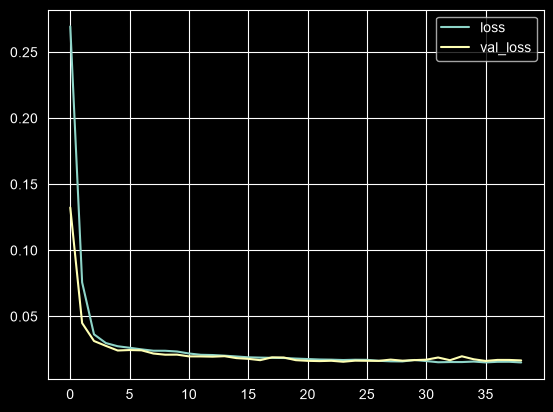

In [37]:
losses_rnn.plot()

loss es el error en train y val_loss el error en validación, por época. La SimpleRNN se detuvo cuando val_loss dejó de mejorar durante 15 épocas.

## 8.2 LSTM

In [38]:
model.fit(generador, epochs=300,
          validation_data=val_generador,
          callbacks=[early_stop], verbose=2)

Epoch 1/300
25/25 - 3s - 127ms/step - loss: 0.0940 - val_loss: 0.0398
Epoch 2/300
25/25 - 0s - 12ms/step - loss: 0.0347 - val_loss: 0.0193
Epoch 3/300
25/25 - 0s - 13ms/step - loss: 0.0323 - val_loss: 0.0182
Epoch 4/300
25/25 - 0s - 19ms/step - loss: 0.0288 - val_loss: 0.0173
Epoch 5/300
25/25 - 0s - 13ms/step - loss: 0.0279 - val_loss: 0.0178
Epoch 6/300
25/25 - 0s - 12ms/step - loss: 0.0261 - val_loss: 0.0178
Epoch 7/300
25/25 - 0s - 18ms/step - loss: 0.0262 - val_loss: 0.0186
Epoch 8/300
25/25 - 0s - 15ms/step - loss: 0.0260 - val_loss: 0.0177
Epoch 9/300
25/25 - 0s - 14ms/step - loss: 0.0237 - val_loss: 0.0169
Epoch 10/300
25/25 - 0s - 16ms/step - loss: 0.0228 - val_loss: 0.0154
Epoch 11/300
25/25 - 0s - 14ms/step - loss: 0.0255 - val_loss: 0.0190
Epoch 12/300
25/25 - 0s - 14ms/step - loss: 0.0241 - val_loss: 0.0174
Epoch 13/300
25/25 - 0s - 15ms/step - loss: 0.0236 - val_loss: 0.0167
Epoch 14/300
25/25 - 0s - 16ms/step - loss: 0.0225 - val_loss: 0.0153
Epoch 15/300
25/25 - 0s - 13

In [39]:
losses = pd.DataFrame(model.history.history)

<Axes: >

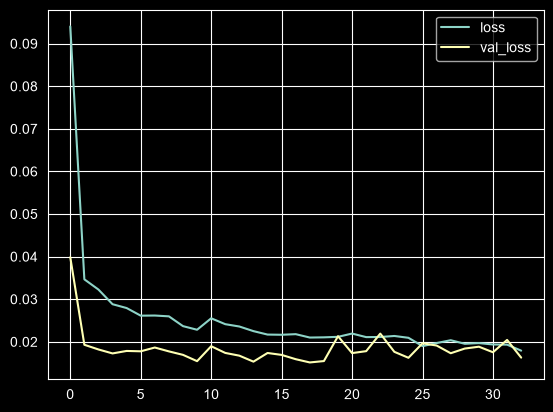

In [40]:
losses.plot()

### Interpretación
La pérdida baja rápido en las primeras épocas y después se estabiliza. Cuando val_loss deja de mejorar, el EarlyStopping detiene el entrenamiento para que el modelo no se aprenda de memoria los datos de train. La pérdida de validación queda más baja que la de train por dos razones: 2022 fue un año tranquilo, mientras que train incluye los brotes de 2015 y 2016, y el Dropout solo se aplica durante el entrenamiento, lo que sube un poco la pérdida de train.

# 9. Evaluación del modelo

## 9.1 Predicción sobre el conjunto de Test

In [41]:
test_predictions = model.predict(test_generador)

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


In [42]:
test_predictions.shape # 101 ventanas de test, cada una con 4 semanas

(101, 4)

In [43]:
# Desescalamos las predicciones para obtener el cambio real ("true_predictions")
true_predictions = scaler_y.inverse_transform(test_predictions)

In [44]:
# Pasamos de cambio a número de casos: casos = exp(log(casos de la última semana) + cambio)
filas = np.arange(test_ind, len(df)-semanas_pred+1) # Primera semana que predice cada ventana
ultimo_log = df['log_casos'].values[filas-1].reshape(-1,1)

casos_pred = np.exp(ultimo_log + true_predictions)

In [45]:
# Predicción de la semana siguiente (semana 1) comparada con los casos reales
test = test.iloc[:len(filas)][['casos_dengue']].copy()
test['Predicción'] = casos_pred[:,0].round()

In [46]:
test

,casos_dengue,Predicción
fecha_inicio_semana,,
2023-01-01,65,22.0
2023-01-08,78,62.0
2023-01-15,57,75.0
2023-01-22,53,55.0
2023-01-29,51,51.0
...,...,...
2024-11-03,494,583.0
2024-11-10,387,487.0
2024-11-17,431,380.0


<Axes: xlabel='fecha_inicio_semana'>

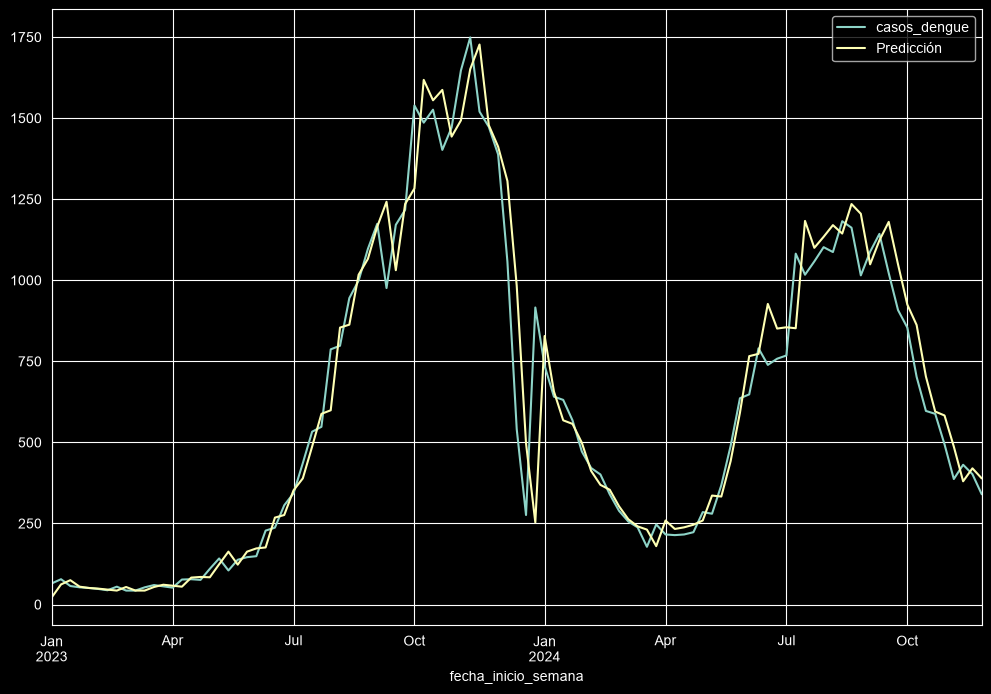

In [47]:
test.plot(figsize=(12,8))

In [48]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [49]:
# RMSE de la semana 1
np.sqrt(mean_squared_error(test['casos_dengue'],test['Predicción']))

np.float64(119.55884254911122)

### Interpretación
La predicción de la semana siguiente sigue muy de cerca a los casos reales, incluso en los brotes de 2023 y 2024. El RMSE de la semana 1 es de unos 120 casos. Es mayor que el error promedio (MAE, unos 71 casos en la tabla por semana) porque el RMSE castiga más los errores grandes. Las primeras semanas de enero de 2023 tienen un error alto porque la última semana conocida es de fin de año, con subregistro.

### Comparación con la SimpleRNN y el baseline estacional
Medimos las 4 semanas de cada ventana. Además del RMSE y el MAE calculamos una precisión del pronóstico: 100 x (1 - suma de errores / suma de casos reales), que indica qué tan cerca estuvo el pronóstico de los casos reales: 100% sería un pronóstico perfecto. Es una medida complementaria; las métricas que pide el proyecto son el RMSE y el MAE.

In [50]:
# Casos reales de las 4 semanas de cada ventana
casos_reales = np.column_stack([df['casos_dengue'].values[filas+k] for k in range(semanas_pred)])

# Baseline estacional: los casos de la misma semana del año anterior (52 semanas antes)
baseline = np.column_stack([df['casos_dengue'].values[filas+k-52] for k in range(semanas_pred)])

# Predicciones de la SimpleRNN (mismos pasos que con el LSTM)
pred_rnn = np.exp(ultimo_log + scaler_y.inverse_transform(model_rnn.predict(test_generador)))

101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [51]:
def metricas(real, pred):
    rmse = np.sqrt(mean_squared_error(real.ravel(), pred.ravel()))
    mae = mean_absolute_error(real.ravel(), pred.ravel())
    precision = 100 * (1 - np.abs(real - pred).sum() / real.sum())
    return round(rmse, 1), round(mae, 1), round(precision, 1)

In [52]:
resultados = pd.DataFrame([metricas(casos_reales, baseline),
                           metricas(casos_reales, pred_rnn),
                           metricas(casos_reales, casos_pred)],
                          index=['Baseline estacional', 'SimpleRNN', 'LSTM'],
                          columns=['RMSE', 'MAE', 'Precisión (%)'])
resultados

,RMSE,MAE,Precisión (%)
Baseline estacional,638.3,455.7,25.2
SimpleRNN,231.3,144.0,76.4
LSTM,173.4,105.8,82.6


In [53]:
# Error del LSTM según cuántas semanas hacia adelante se predice
por_semana = pd.DataFrame([metricas(casos_reales[:,k], casos_pred[:,k]) for k in range(semanas_pred)],
                          index=['Semana 1', 'Semana 2', 'Semana 3', 'Semana 4'],
                          columns=['RMSE', 'MAE', 'Precisión (%)'])
por_semana

,RMSE,MAE,Precisión (%)
Semana 1,119.6,71.0,88.3
Semana 2,162.1,97.9,83.9
Semana 3,190.1,117.3,80.8
Semana 4,208.7,137.2,77.5


Mientras más lejos se predice, más difícil es: la semana 1 tiene una precisión cercana al 88% y la semana 4 cercana al 77%. Esto es normal en cualquier pronóstico, porque entre más tiempo pasa, más cosas pueden cambiar.

<Axes: xlabel='fecha_inicio_semana'>

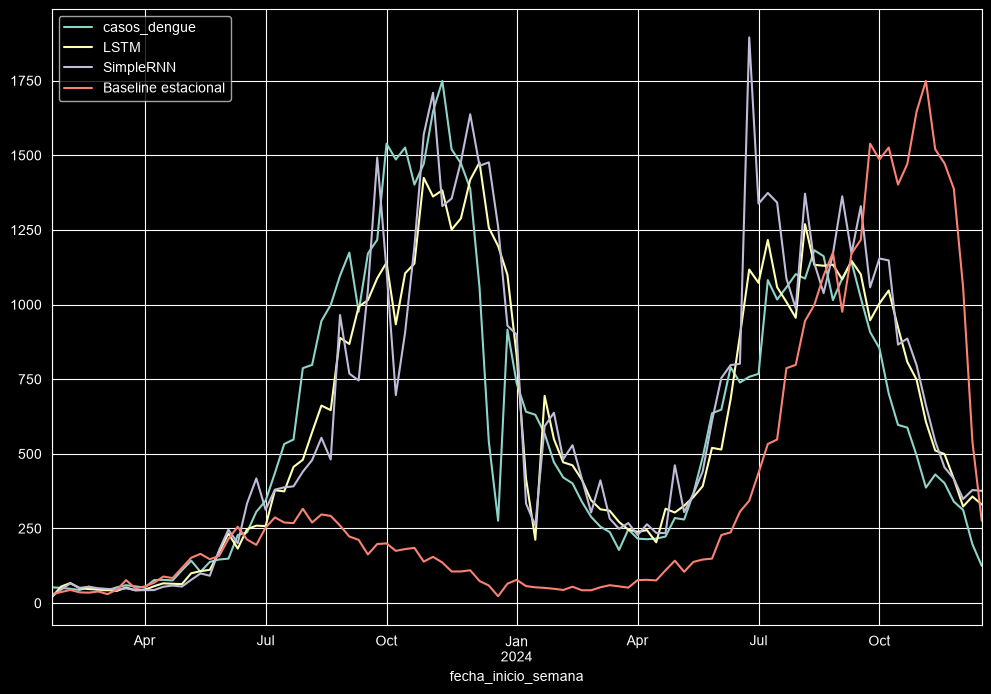

In [54]:
# Predicción a 4 semanas de los dos modelos y el baseline
pred_4 = pd.DataFrame({'casos_dengue': casos_reales[:,3],
                       'LSTM': casos_pred[:,3],
                       'SimpleRNN': pred_rnn[:,3],
                       'Baseline estacional': baseline[:,3]},
                      index=df.index[filas+3])
pred_4.plot(figsize=(12,8))

### Interpretación
- El LSTM tiene mucho menos error que el baseline estacional, que es la meta del proyecto. El baseline falla porque copia el año anterior: 2022 fue tranquilo y 2023 fue de brote, y en 2024 el brote llegó semanas antes que en 2023, así que el baseline queda desfasado.
- El LSTM también le gana a la SimpleRNN. La SimpleRNN es más inestable y en algunas semanas exagera los picos, porque le cuesta recordar información de muchas semanas atrás. El LSTM tiene memoria para eso.
- El error sube mientras más lejos se predice: la semana 1 es la que mejor sale y la semana 4 la que peor.
- A 4 semanas, el LSTM detecta cuándo los casos empiezan a subir, pero se queda un poco corto al inicio de los brotes.
- Los errores más grandes están en el cambio de año, por el subregistro de fin de año que encontramos en el EDA. En diciembre se reportan menos casos y se acumulan en enero, y eso no lo puede anticipar ningún modelo.

## 9.2 Predicción de nuevos datos (forecast)

In [55]:
# Cogemos todos los datos originales y escalamos en base a ellos
full_scaler = MinMaxScaler()
full_scaler_y = MinMaxScaler()
scaled_full_data = full_scaler.fit_transform(df[columnas])
scaled_full_y = full_scaler_y.fit_transform(df[columnas_objetivo])

In [56]:
generador = TimeseriesGenerator(scaled_full_data, scaled_full_y, length=longitud, batch_size=tamaño_batch,
                                end_index=len(df)-semanas_pred)

In [57]:
tf.keras.utils.set_random_seed(42)

model = Sequential()
model.add(LSTM(64, activation='relu', return_sequences=True, input_shape=(longitud, n_variables)))
model.add(LSTM(32, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(semanas_pred))
model.compile(optimizer='adam', loss='mse')

# Ajustamos el modelo, escogemos el número de epochs en base al entrenamiento anterior (no tiene sentido EarlyStopping puesto que no tenemos ahora datos de validación con los que comparar)
epocas = losses['val_loss'].idxmin() + 1
model.fit(generador, epochs=epocas, verbose=2)

Epoch 1/18
35/35 - 3s - 87ms/step - loss: 0.0827
Epoch 2/18
35/35 - 0s - 13ms/step - loss: 0.0323
Epoch 3/18
35/35 - 0s - 14ms/step - loss: 0.0287
Epoch 4/18
35/35 - 0s - 14ms/step - loss: 0.0243
Epoch 5/18
35/35 - 0s - 13ms/step - loss: 0.0243
Epoch 6/18
35/35 - 0s - 14ms/step - loss: 0.0227
Epoch 7/18
35/35 - 0s - 14ms/step - loss: 0.0230
Epoch 8/18
35/35 - 0s - 13ms/step - loss: 0.0218
Epoch 9/18
35/35 - 1s - 19ms/step - loss: 0.0199
Epoch 10/18
35/35 - 1s - 15ms/step - loss: 0.0202
Epoch 11/18
35/35 - 1s - 20ms/step - loss: 0.0206
Epoch 12/18
35/35 - 1s - 16ms/step - loss: 0.0189
Epoch 13/18
35/35 - 0s - 14ms/step - loss: 0.0193
Epoch 14/18
35/35 - 1s - 17ms/step - loss: 0.0189
Epoch 15/18
35/35 - 1s - 17ms/step - loss: 0.0190
Epoch 16/18
35/35 - 0s - 12ms/step - loss: 0.0187
Epoch 17/18
35/35 - 1s - 15ms/step - loss: 0.0166
Epoch 18/18
35/35 - 1s - 18ms/step - loss: 0.0177


In [58]:
# Última ventana de 26 semanas para predecir las 4 semanas siguientes
primer_batch = scaled_full_data[-longitud:]
batch_actual = primer_batch.reshape((1, longitud, n_variables))

forecast = full_scaler_y.inverse_transform(model.predict(batch_actual))[0]
forecast = np.exp(df['log_casos'].iloc[-1] + forecast) # De cambio a número de casos

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step


Creamos el nuevo índice de tiempos para el forecast

In [59]:
# Creamos el índice para que empiece en la semana siguiente a la última de nuestros datos (2024-12-22)
forecast_index = pd.date_range(start='2024-12-29', periods=semanas_pred, freq='7D')

In [60]:
forecast_df = pd.DataFrame(data=forecast.round(), index=forecast_index, columns=['Forecast'])

In [61]:
forecast_df

,Forecast
2024-12-29,110.0
2025-01-05,99.0
2025-01-12,85.0
2025-01-19,76.0


Estos son los casos que el modelo pronostica para las 4 semanas siguientes al último dato (diciembre 2024 - enero 2025). Siguen la tendencia a la baja que traían los casos al final de 2024.

(2819.0, 2875.0)

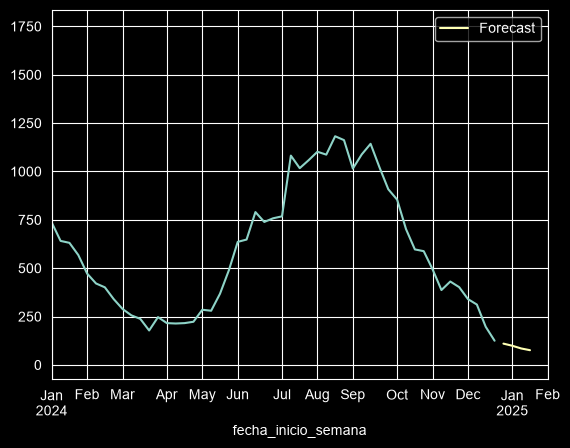

In [62]:
#Unimos ambos plots en la misma figura y hacemos zoom
ax = df['casos_dengue'].plot()
forecast_df.plot(ax=ax)
plt.xlim('2024-01-01','2025-02-01')

El forecast cae en las primeras semanas de 2025, justo después del fin de año. Como vimos en el EDA, en esas semanas hay un salto por el subregistro de diciembre, así que hay que tomarlo con cuidado.

In [63]:
model.save('../models/modelo_lstm_casos.h5')

In [64]:
import joblib

# La app también necesita los escaladores para preparar los datos y desescalar la predicción
joblib.dump({'scaler': full_scaler, 'scaler_y': full_scaler_y, 'columnas': columnas,
             'longitud': longitud, 'semanas_pred': semanas_pred},
            '../models/modelo_lstm_casos_escaladores.pkl')

['../models/modelo_lstm_casos_escaladores.pkl']

Se guardan dos archivos en la carpeta models: el modelo entrenado (.h5) y los escaladores (.pkl). La app necesita los dos: los escaladores para preparar las últimas 26 semanas igual que en el entrenamiento y para desescalar la predicción.

## 9.3 Pronóstico y escenarios para 2025 y 2026
Los datos llegan hasta diciembre de 2024. Para 2025 y 2026 hacemos lo mismo que en el ejercicio de clase de temperatura (forecast de 36 meses): el modelo predice 4 semanas, las agregamos a la ventana como si fueran datos, y volvemos a predecir. Lo repetimos 26 veces (26 x 4 = 104 semanas = 2 años).

Siguiendo la recomendación del profesor:
- Solo las **primeras 4 semanas** son un **pronóstico**. Las demás son **posibles escenarios**, porque en cada repetición el modelo usa sus propias predicciones y el error se va acumulando.
- Para el clima de 2025-2026 usamos el **clima real de NASA POWER**, en lugar del promedio de cada semana.

### Clima real de NASA POWER
El clima de 2025-2026 lo descargamos con el script `src/clima_nasa.py`, que usa la API de NASA POWER con el mismo método del dataset del proyecto (LEEME): clima diario de las 7 cabeceras de provincia, ponderado por población y agrupado por semana. El script también descarga 2014-2024 y lo compara con el clima del dataset: en las 574 semanas la correlación fue 1.0 y la diferencia 0.0 en las cuatro variables, o sea que el clima de 2025-2026 se calculó igual que el del dataset.

El resultado quedó guardado en `data/processed/clima_nasa_2025_2026.csv`. Así el notebook no necesita internet: solo lee el archivo.

In [65]:
clima_nasa = pd.read_csv('../data/processed/clima_nasa_2025_2026.csv', index_col='fecha_inicio_semana', parse_dates=True)
clima_nasa['log_lluvia'] = np.log1p(clima_nasa['lluvia_mm']) # Igual que en el EDA

In [66]:
print('Semanas con clima real:', len(clima_nasa))
print('Desde', clima_nasa.index.min().date(), 'hasta', clima_nasa.index.max().date())
clima_nasa.head()

Semanas con clima real: 96
Desde 2024-12-29 hasta 2026-10-25


,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,log_lluvia
fecha_inicio_semana,,,,,
2024-12-29,51.3,25.8,20.5,89.6,3.956996
2025-01-05,15.4,26.8,21.1,88.4,2.797281
2025-01-12,2.4,27.1,20.1,84.5,1.223775
2025-01-19,15.8,27.4,20.0,83.9,2.821379
2025-01-26,28.1,27.8,20.7,83.8,3.370738


NASA POWER publica los datos con unos días de atraso, así que el clima real llega hasta finales de octubre de 2026. Para las últimas semanas de 2026, que todavía no han pasado, usamos el clima promedio de esa semana del año en 2014-2024.

In [67]:
# Clima promedio de cada semana epidemiológica (2014-2024), para las semanas sin dato real
clima = ['temp_min_c', 'log_lluvia', 'humedad_rel_pct', 'temp_max_c']
clima_promedio = df.groupby('semana_epi')[clima].mean()
clima_promedio.head()

,temp_min_c,log_lluvia,humedad_rel_pct,temp_max_c
semana_epi,,,,
1,19.881818,2.299784,83.700000,27.136364
2,19.909091,2.481662,83.172727,26.945455
3,19.818182,1.975027,81.954545,27.245455
4,19.827273,1.869332,80.563636,27.527273
5,19.636364,1.967937,78.600000,27.763636


Para las semanas futuras también necesitamos la semana epidemiológica. Usamos la misma regla que traen los datos: las semanas empiezan en domingo y la semana 1 es la que contiene el 3 de enero.

In [68]:
def semana_epidemiologica(fecha):
    for anio in [fecha.year + 1, fecha.year, fecha.year - 1]:
        tres_enero = pd.Timestamp(anio, 1, 3)
        inicio = tres_enero - pd.Timedelta(days=(tres_enero.weekday() + 1) % 7) # Domingo de esa semana
        if fecha >= inicio:
            return anio, (fecha - inicio).days // 7 + 1

In [69]:
# Comprobamos que la regla da lo mismo que los datos en las 574 semanas
all(semana_epidemiologica(fecha) == (anio, semana)
    for fecha, anio, semana in zip(df.index, df['anio'], df['semana_epi']))

True

<Axes: title={'center': 'Temperatura mínima 2025-2026: real vs promedio'}, xlabel='fecha_inicio_semana'>

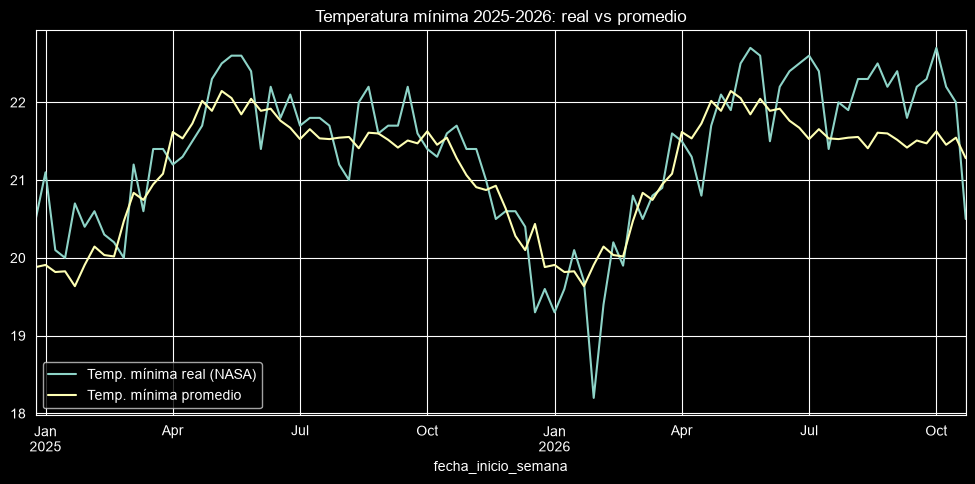

In [70]:
# Comparamos el clima real de 2025-2026 con el clima promedio de esas mismas semanas
semanas_futuras = [semana_epidemiologica(f)[1] for f in clima_nasa.index]
comparacion_clima = pd.DataFrame({
    'Temp. mínima real (NASA)': clima_nasa['temp_min_c'].values,
    'Temp. mínima promedio': clima_promedio.loc[semanas_futuras, 'temp_min_c'].values,
}, index=clima_nasa.index)
comparacion_clima.plot(figsize=(12,5), title='Temperatura mínima 2025-2026: real vs promedio')

Usamos la temperatura mínima para comparar porque es la variable del clima que más se relaciona con los casos (EDA). Las semanas en que el clima real es más caliente o más frío que el promedio cambian el resultado del escenario.

### Escenarios
Armamos el mismo ciclo del ejercicio de clase dentro de una función, para poder correrlo con dos climas distintos y comparar:
- **Escenario con clima real (NASA POWER)**: el que recomendó el profesor.
- **Escenario con clima promedio**: el que usábamos antes, como comparación.

In [71]:
periodos = 26 # 26 bloques de 4 semanas = 104 semanas (2025 y 2026)

def escenario(clima_real=None):
    historia = df[columnas].copy() # Datos reales; aquí se van agregando las semanas pronosticadas
    resultado = []

    for i in range(periodos):

        # Última ventana de 26 semanas (reales o ya pronosticadas)
        batch_actual = full_scaler.transform(historia.iloc[-longitud:]).reshape((1, longitud, n_variables))

        # Predecimos el cambio de las 4 semanas siguientes y lo desescalamos
        cambio = full_scaler_y.inverse_transform(model.predict(batch_actual, verbose=0))[0]
        ultimo_log = historia['log_casos'].iloc[-1]

        # Agregamos las 4 semanas nuevas a la historia (casos pronosticados + clima de esa semana)
        for k in range(semanas_pred):
            fecha = historia.index[-1] + pd.Timedelta(weeks=1)
            anio, semana = semana_epidemiologica(fecha)
            if clima_real is not None and fecha in clima_real.index:
                nueva = clima_real.loc[fecha, clima].copy()
                origen = 'NASA POWER (real)'
            else:
                nueva = clima_promedio.loc[semana].copy()
                origen = 'Promedio de la semana'
            nueva['log_casos'] = ultimo_log + cambio[k]
            nueva['semana_sin'] = np.sin(2*np.pi*semana/52)
            nueva['semana_cos'] = np.cos(2*np.pi*semana/52)
            historia.loc[fecha] = nueva[columnas]
            resultado.append([fecha, anio, semana, round(float(np.exp(nueva['log_casos']))), origen])

    resultado = pd.DataFrame(resultado, columns=['fecha', 'anio', 'semana_epi', 'Forecast', 'Clima']).set_index('fecha')

    # Solo las primeras 4 semanas son pronóstico; el resto son escenarios
    resultado['Tipo'] = ['Pronóstico'] * semanas_pred + ['Escenario'] * (len(resultado) - semanas_pred)
    return resultado

In [72]:
escenario_real = escenario(clima_nasa)  # Clima real de NASA POWER
escenario_promedio = escenario()        # Clima promedio de cada semana

In [73]:
escenario_real.head(8)

,anio,semana_epi,Forecast,Clima,Tipo
fecha,,,,,
2024-12-29,2025,1,110,NASA POWER (real),Pronóstico
2025-01-05,2025,2,99,NASA POWER (real),Pronóstico
2025-01-12,2025,3,85,NASA POWER (real),Pronóstico
2025-01-19,2025,4,76,NASA POWER (real),Pronóstico
2025-01-26,2025,5,68,NASA POWER (real),Escenario
2025-02-02,2025,6,63,NASA POWER (real),Escenario
2025-02-09,2025,7,55,NASA POWER (real),Escenario
2025-02-16,2025,8,51,NASA POWER (real),Escenario


In [74]:
# ¿De dónde salió el clima de cada semana del escenario?
escenario_real['Clima'].value_counts()

Clima
NASA POWER (real)        96
Promedio de la semana     8
Name: count, dtype: int64

Para tener una referencia, comparamos con un "año típico": la mediana de los casos de cada semana epidemiológica en 2014-2024.

In [75]:
# Año típico: mediana de los casos de cada semana epidemiológica (2014-2024)
mediana_semana = df.groupby('semana_epi')['casos_dengue'].median()
escenario_real['Año típico'] = escenario_real['semana_epi'].map(mediana_semana)

In [76]:
# Total de casos por año en cada escenario, comparado con el año típico
pd.DataFrame({
    'Escenario clima real (NASA)': escenario_real.groupby('anio')['Forecast'].sum(),
    'Escenario clima promedio': escenario_promedio.groupby('anio')['Forecast'].sum(),
    'Año típico': escenario_real.groupby('anio')['Año típico'].sum(),
})

,Escenario clima real (NASA),Escenario clima promedio,Año típico
anio,,,
2025,2418,2836,9399.0
2026,1848,1498,9399.0


In [77]:
df.groupby('anio')['casos_dengue'].sum()

anio
2014    11049
2015    17485
2016    23319
2017     5561
2018     2735
2019     9400
2020    10056
2021     5174
2022     7485
2023    30649
2024    31259
Name: casos_dengue, dtype: int64

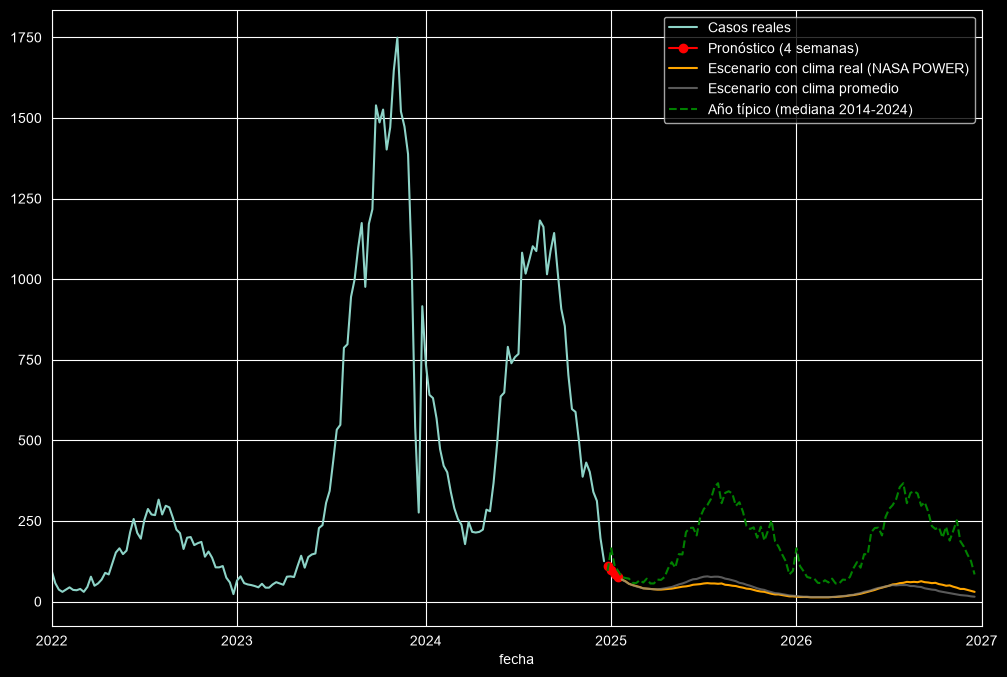

In [78]:
#Unimos los datos reales, el pronóstico y los escenarios en la misma figura
pronostico_4 = escenario_real[escenario_real['Tipo'] == 'Pronóstico']['Forecast']
escenario_r = escenario_real[escenario_real['Tipo'] == 'Escenario']['Forecast']
escenario_p = escenario_promedio[escenario_promedio['Tipo'] == 'Escenario']['Forecast']

ax = df['casos_dengue'].plot(figsize=(12,8), label='Casos reales')
pronostico_4.plot(ax=ax, marker='o', color='red', label='Pronóstico (4 semanas)')
escenario_r.plot(ax=ax, color='orange', label='Escenario con clima real (NASA POWER)')
escenario_p.plot(ax=ax, color='gray', alpha=0.7, label='Escenario con clima promedio')
escenario_real['Año típico'].plot(ax=ax, style='--', color='green', label='Año típico (mediana 2014-2024)')
plt.xlim('2022-01-01','2027-01-01')
plt.legend()

### Interpretación
- Las primeras 4 semanas (en rojo) son el pronóstico: es lo mismo que en la sección 9.2 y es la parte confiable, porque usa los casos reales más recientes.
- Desde la semana 5 son escenarios. Mantienen la forma de cada año (los casos bajan a inicios de año y suben a mitad de año), pero el nivel queda por debajo del año típico, porque el modelo sigue la bajada que traían los casos al final de 2024 después del brote.
- Con el clima real de NASA POWER el escenario cambia respecto al clima promedio, sobre todo en 2026. Eso muestra que el modelo sí usa el clima: semanas más calientes o más lluviosas que el promedio suben el riesgo.
- Ninguno de los escenarios puede anticipar un brote nuevo, porque los brotes dependen de cosas que no están en los datos (como el serotipo del virus o las campañas de control). Por eso son escenarios posibles y no un pronóstico. En la sección 10 comprobamos qué tan confiables son.

## 9.4 Comparación con el umbral endémico
En el dashboard, el pronóstico del LSTM se grafica contra el **umbral endémico**: el nivel a partir del cual los casos se consideran más altos de lo normal para esa época del año.

Usamos el mismo umbral de `vectoria_acciones.csv`. Según el LEEME, es el percentil 75 de la suma de casos de esas mismas 4 semanas en los años anteriores (de 3 a 5 años). Como indicó el profesor, el umbral **no es semanal: es la suma de las 4 semanas**. Por eso lo comparamos de las dos formas que él sugirió:
- **Suma del pronóstico de 4 semanas contra el umbral.**
- **Umbral entre 4**, como aproximación semanal.

Para poder calcularlo en cualquier semana (incluidas 2025 y 2026), lo calculamos con los datos reales y comprobamos que da lo mismo que el CSV.

In [79]:
# Suma de los casos reales de las 4 semanas siguientes a cada semana
suma_4 = df['casos_dengue'][::-1].rolling(semanas_pred).sum()[::-1].shift(-1)
suma_4_por_semana = dict(zip(zip(df['anio'], df['semana_epi']), suma_4))

def umbral_endemico(anio, semana):
    previos = [suma_4_por_semana.get((anio - k, semana)) for k in range(1, 6)] # De 1 a 5 años antes
    previos = [v for v in previos if v is not None and not np.isnan(v)]
    return round(np.percentile(previos, 75)) if len(previos) >= 3 else np.nan # Necesita al menos 3 años

In [80]:
# Comprobamos que da lo mismo que el umbral de vectoria_acciones.csv
acciones = pd.read_csv('../data/raw/vectoria_acciones.csv', parse_dates=['fecha_inicio_semana'])
umbral_csv = acciones.groupby('fecha_inicio_semana')[['anio', 'semana_epi', 'casos_umbral_endemico']].first()
umbral_nuestro = np.array([umbral_endemico(a, s) for a, s in zip(umbral_csv['anio'], umbral_csv['semana_epi'])])

print('Semanas comparadas:', len(umbral_csv))
print('Coinciden con el CSV del profesor:', round(np.mean(umbral_nuestro == umbral_csv['casos_umbral_endemico'].values) * 100, 1), '%')

Semanas comparadas: 412
Coinciden con el CSV del profesor: 100.0 %


### Pronóstico contra el umbral en el test (2023-2024)
Para cada semana del test comparamos la suma de los casos reales de las 4 semanas siguientes, la suma del pronóstico del LSTM y el umbral endémico.

In [81]:
semana_elegida = filas - 1 # Semana desde la que se hace cada pronóstico

comparacion_umbral = pd.DataFrame({
    'Casos reales (4 semanas)': casos_reales.sum(axis=1),
    'Pronóstico LSTM (4 semanas)': casos_pred.sum(axis=1).round(),
    'Umbral endémico': [umbral_endemico(a, s) for a, s in zip(df['anio'].values[semana_elegida], df['semana_epi'].values[semana_elegida])],
}, index=df.index[semana_elegida])
comparacion_umbral['2 x umbral'] = 2 * comparacion_umbral['Umbral endémico']

<Axes: title={'center': 'Suma de 4 semanas: casos reales, pronóstico y umbral endémico'}, xlabel='fecha_inicio_semana'>

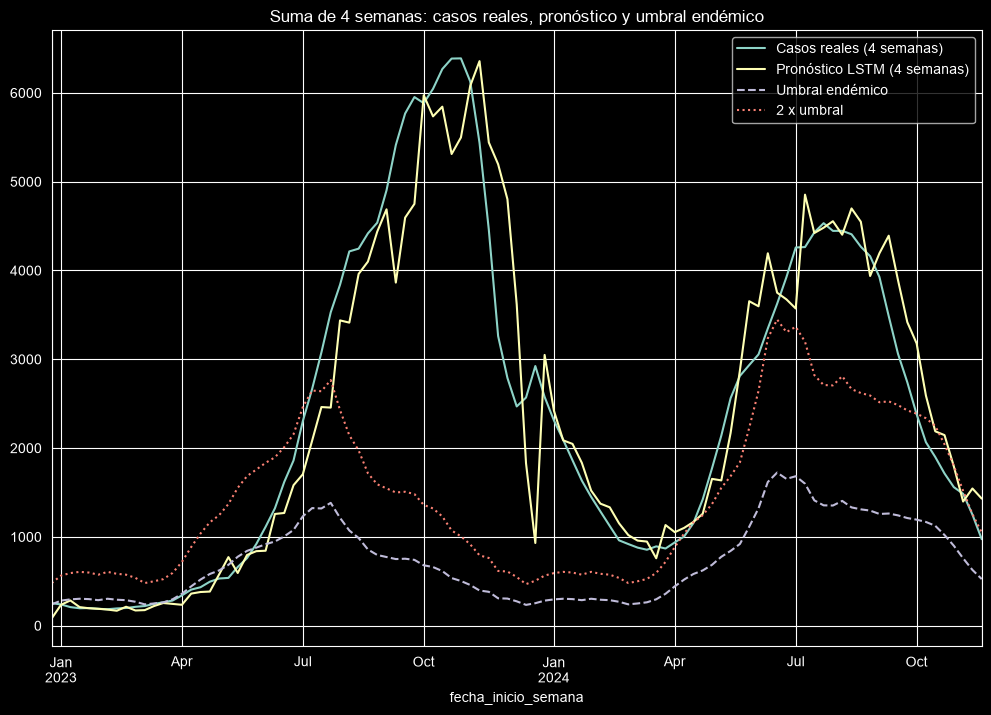

In [82]:
comparacion_umbral.plot(figsize=(12,8), style=['-', '-', '--', ':'], title='Suma de 4 semanas: casos reales, pronóstico y umbral endémico')

In [83]:
# ¿El pronóstico detecta cuándo los casos superan el umbral?
def situacion(casos, umbral):
    if casos > 2 * umbral:
        return 'Más del doble del umbral'
    if casos > umbral:
        return 'Sobre el umbral'
    return 'Por debajo del umbral'

situacion_real = [situacion(c, u) for c, u in zip(comparacion_umbral['Casos reales (4 semanas)'], comparacion_umbral['Umbral endémico'])]
situacion_pred = [situacion(c, u) for c, u in zip(comparacion_umbral['Pronóstico LSTM (4 semanas)'], comparacion_umbral['Umbral endémico'])]

pd.crosstab(pd.Series(situacion_real, name='Situación real'), pd.Series(situacion_pred, name='Situación pronosticada'))

Situación pronosticada,Más del doble del umbral,Por debajo del umbral,Sobre el umbral
Situación real,,,
Más del doble del umbral,60,0,3
Por debajo del umbral,0,19,1
Sobre el umbral,7,4,7


In [84]:
acierto = np.mean(np.array(situacion_real) == np.array(situacion_pred)) * 100
print(f'El pronóstico acierta la situación frente al umbral en el {acierto:.1f} % de las semanas de test')

El pronóstico acierta la situación frente al umbral en el 85.1 % de las semanas de test


### Interpretación
- El umbral calculado coincide al 100% con el de `vectoria_acciones.csv`, así que podemos usarlo para cualquier semana.
- En 2023 y 2024 los casos superaron con creces el umbral: fueron los brotes más grandes de la serie. El pronóstico del LSTM sigue esa subida, así que en la mayoría de las semanas marca correctamente si los casos van a estar por debajo, sobre el umbral o en más del doble (la tabla muestra en qué semanas acierta y en cuáles no).
- Esto es lo que necesita el dashboard: no solo cuántos casos, sino si esos casos son más de lo normal para esa época del año. Esa comparación también es la base de las recomendaciones del Módulo 3 (por ejemplo, la alerta sanitaria se da cuando los casos superan el doble del umbral).

### Pronóstico de las primeras 4 semanas de 2025 contra el umbral
Usamos las dos formas que indicó el profesor: la suma del pronóstico contra el umbral, y el umbral entre 4 como aproximación semanal.

In [85]:
anio_ultimo, semana_ultima = semana_epidemiologica(df.index[-1])
umbral_2025 = umbral_endemico(anio_ultimo, semana_ultima)

print('Suma del pronóstico de las 4 semanas:', forecast_df['Forecast'].sum())
print('Umbral endémico de esas 4 semanas:', umbral_2025)
print('Situación:', situacion(forecast_df['Forecast'].sum(), umbral_2025))

Suma del pronóstico de las 4 semanas: 370.0
Umbral endémico de esas 4 semanas: 598
Situación: Por debajo del umbral


In [86]:
# Aproximación semanal: umbral entre 4, para graficarlo junto al pronóstico de cada semana
forecast_df['Umbral semanal (aprox.)'] = umbral_2025 / semanas_pred
forecast_df

,Forecast,Umbral semanal (aprox.)
2024-12-29,110.0,149.5
2025-01-05,99.0,149.5
2025-01-12,85.0,149.5
2025-01-19,76.0,149.5


# 10. Uso del modelo desde la clase PronosticadorDengue
Los mismos pasos de este notebook están organizados en la clase PronosticadorDengue (src/train/lstm.py), para usarlos desde la app de Streamlit. Comprobamos que la clase carga el modelo guardado y da el mismo forecast.

In [87]:
import sys
sys.path.append('..') # Para encontrar la carpeta src/

from src.train.lstm import PronosticadorDengue

In [88]:
datos = pd.read_csv('../data/processed/dengue_nacional_procesado.csv', parse_dates=['fecha_inicio_semana'])

pronosticador, modelo_cargado = PronosticadorDengue.cargar(datos, '../models')
pronosticador.pronosticar_futuro(modelo_cargado)

,Forecast
2024-12-29,110.0
2025-01-05,99.0
2025-01-12,85.0
2025-01-19,76.0


Para el dashboard, el usuario elige una semana y la clase pronostica las 4 semanas siguientes. Si la semana es de 2014-2024, también muestra los casos reales para comparar. Si es de 2025 o 2026, usa el escenario con clima real de la sección 9.3, y la columna Tipo indica que es un escenario.

In [89]:
# Semana dentro de los datos: pronóstico y casos reales
pronosticador.pronosticar_desde(modelo_cargado, '2024-06-01')

,Forecast,Casos reales,Año típico,Tipo,Clima
2024-06-02,541.0,636,215.0,Pronóstico,Datos reales
2024-06-09,574.0,648,228.0,Pronóstico,Datos reales
2024-06-16,623.0,790,229.0,Pronóstico,Datos reales
2024-06-23,668.0,739,205.0,Pronóstico,Datos reales


In [90]:
# Semana de 2025: sale del escenario con clima real (da lo mismo que la sección 9.3)
pronosticador.pronosticar_desde(modelo_cargado, '2025-07-01')

,Forecast,Casos reales,Año típico,Tipo,Clima
fecha,,,,,
2025-07-06,56,NaN,287.0,Escenario,NASA POWER (real)
2025-07-13,57,NaN,299.0,Escenario,NASA POWER (real)
2025-07-20,56,NaN,318.0,Escenario,NASA POWER (real)
2025-07-27,56,NaN,355.0,Escenario,NASA POWER (real)


In [91]:
escenario_real.loc['2025-07-06':'2025-07-27', ['Forecast', 'Tipo', 'Clima']]

,Forecast,Tipo,Clima
fecha,,,
2025-07-06,56,Escenario,NASA POWER (real)
2025-07-13,57,Escenario,NASA POWER (real)
2025-07-20,56,Escenario,NASA POWER (real)
2025-07-27,56,Escenario,NASA POWER (real)


Para la pestaña "Elegir semana" del dashboard, la clase también compara el pronóstico con el umbral endémico (sección 9.4):

In [92]:
pronosticador.comparar_con_umbral(modelo_cargado, '2024-06-01')

{'Pronóstico 4 semanas': 2406,
 'Umbral 4 semanas': 920.0,
 'Umbral semanal (aprox.)': 230.0,
 'Razón pronóstico / umbral': 2.62,
 'Situación': 'Más del doble del umbral',
 'Tipo': 'Pronóstico'}

### Comprobación: ¿qué tan confiables son los escenarios?
Para saber si los escenarios de la sección 9.3 sirven, repetimos exactamente lo mismo pero como si estuviéramos a inicios de 2023: entrenamos solo con los datos hasta 2022 y armamos los escenarios de 2023 y 2024. Como esos años sí los tenemos, podemos comparar contra lo que pasó en realidad. Lo hacemos con el clima real de 2023-2024 (como haríamos con NASA POWER) y con el clima promedio.

In [93]:
# Datos hasta 2022 (como si estuviéramos a inicios de 2023)
datos_2022 = datos[datos['fecha_inicio_semana'] < '2023-01-01']
datos_2023_2024 = datos[datos['fecha_inicio_semana'] >= '2023-01-01'].copy()

prueba = PronosticadorDengue(datos_2022)
prueba.dividir(tamaño_test=52, tamaño_val=52) # Solo para escoger el número de épocas con EarlyStopping
prueba.escalar()
gen, val_gen, test_gen = prueba.crear_generadores()
modelo_prueba = prueba.construir_lstm()
losses_prueba = prueba.entrenar(modelo_prueba, gen, val_gen)

# Igual que en 9.2: modelo final con todos los datos hasta 2022
prueba.escalar(hasta=len(prueba.df))
modelo_prueba = prueba.construir_lstm()
prueba.entrenar(modelo_prueba, prueba.crear_generador_completo(), epochs=int(losses_prueba['val_loss'].idxmin()) + 1)

# Igual que en 9.3: escenarios de 104 semanas (2023 y 2024) con clima real y con clima promedio
escenario_2023_2024_real = prueba.pronosticar_largo_plazo(modelo_prueba, semanas=104, clima_futuro=datos_2023_2024)
escenario_2023_2024_promedio = prueba.pronosticar_largo_plazo(modelo_prueba, semanas=104)

In [94]:
real_2023_2024 = datos_2023_2024['casos_dengue'].values

comparacion = pd.DataFrame({
    'Escenario 2 años, clima real': PronosticadorDengue.evaluar(real_2023_2024, escenario_2023_2024_real['Forecast'].values),
    'Escenario 2 años, clima promedio': PronosticadorDengue.evaluar(real_2023_2024, escenario_2023_2024_promedio['Forecast'].values),
    'Año típico': PronosticadorDengue.evaluar(real_2023_2024, escenario_2023_2024_real['Año típico'].values),
    'LSTM a 4 semanas (sección 9.1)': resultados.loc['LSTM'].to_dict(),
}).T
comparacion

,RMSE,MAE,Precisión (%)
"Escenario 2 años, clima real",563.5,390.7,34.4
"Escenario 2 años, clima promedio",668.9,512.6,13.9
Año típico,617.1,452.8,23.9
LSTM a 4 semanas (sección 9.1),173.4,105.8,82.6


<Axes: xlabel='fecha'>

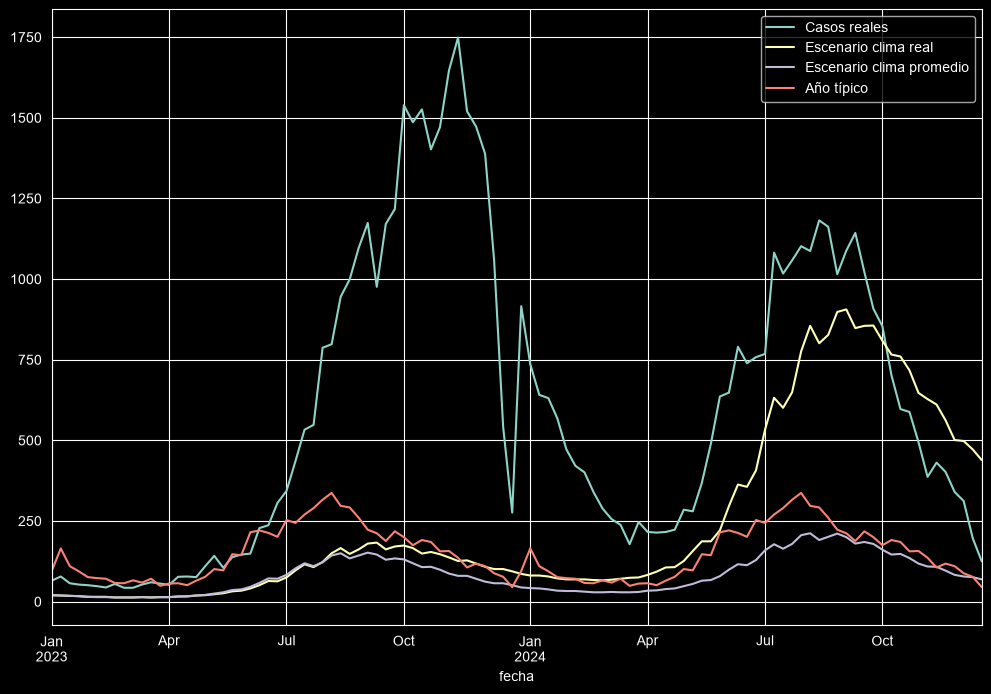

In [95]:
grafico = pd.DataFrame({
    'Casos reales': real_2023_2024,
    'Escenario clima real': escenario_2023_2024_real['Forecast'].values,
    'Escenario clima promedio': escenario_2023_2024_promedio['Forecast'].values,
    'Año típico': escenario_2023_2024_real['Año típico'].values,
}, index=escenario_2023_2024_real.index)
grafico.plot(figsize=(12,8))

### Interpretación
- Usar el clima real mejora el escenario: tiene menos error que con el clima promedio y que el año típico. Esto confirma la recomendación del profesor de usar el clima de NASA POWER en lugar del promedio.
- En el gráfico se ve por qué: con el clima real, el escenario de 2024 sube con fuerza a mitad de año y sigue la forma del brote de 2024, aunque se queda por debajo. Con el clima promedio eso no pasa.
- Aun así, ningún escenario anticipó el brote de 2023, el más grande de la serie: nada en los datos hasta 2022 lo anunciaba.
- En cambio, el LSTM pronosticando solo 4 semanas (sección 9.1) sí siguió el brote, porque cada pronóstico usa los casos reales más recientes.
- Conclusión: las primeras 4 semanas son el pronóstico confiable y el resto son escenarios posibles, como indicó el profesor. En el dashboard, las semanas de 2025-2026 se muestran como escenario, junto al año típico como referencia.

# 11. Conclusiones
- Entrenamos los dos modelos que pide el proyecto con ventanas de 26 semanas para predecir 4 semanas: una SimpleRNN de base y un LSTM (64, 32, Dropout 0.2, Dense 4).
- El LSTM es el mejor: tiene menos error que el baseline estacional y que la SimpleRNN (tabla de la sección 9.1).
- Las decisiones clave salieron del EDA: trabajar con log(casos), usar los casos pasados como entrada además del clima, y predecir el cambio respecto a la última semana para poder pronosticar brotes más grandes que los de entrenamiento.
- Limitaciones: el error sube mientras más lejos se predice, el subregistro de fin de año causa errores en diciembre y enero, y solo hay 574 semanas con pocos brotes grandes.
- Para 2025 y 2026, siguiendo la recomendación del profesor, las primeras 4 semanas son el pronóstico y el resto son posibles escenarios, con el clima real de NASA POWER (descargado con src/clima_nasa.py con el mismo método del dataset). Lo comprobamos con 2023-2024: el clima real mejora el escenario, pero ningún escenario anticipa un brote nuevo, por eso el pronóstico confiable es el de 4 semanas.
- El pronóstico se compara con el umbral endémico, sumando las 4 semanas (o dividiendo el umbral entre 4), como indicó el profesor. Calculamos el umbral igual que en vectoria_acciones.csv (coincide al 100%), así que sirve para cualquier semana del dashboard.
- El modelo final, entrenado con toda la serie, quedó guardado en models/modelo_lstm_casos.h5 con sus escaladores, listo para la app y para el Módulo 3 (ANN).